# What drives the price of a car?

![](images/kurt.jpeg)

**OVERVIEW**

In this application, you will explore a dataset from Kaggle. The original dataset contained information on 3 million used cars. The provided dataset contains information on 426K cars to ensure speed of processing.  Your goal is to understand what factors make a car more or less expensive.  As a result of your analysis, you should provide clear recommendations to your client -- a used car dealership -- as to what consumers value in a used car.

### CRISP-DM Framework

<center>
    <img src = images/crisp.png width = 50%/>
</center>


To frame the task, throughout our practical applications, we will refer back to a standard process in industry for data projects called CRISP-DM.  This process provides a framework for working through a data problem.  Your first step in this application will be to read through a brief overview of CRISP-DM [here](https://mo-pcco.s3.us-east-1.amazonaws.com/BH-PCMLAI/module_11/readings_starter.zip).  After reading the overview, answer the questions below.

### Business Understanding

From a business perspective, we are tasked with identifying key drivers for used car prices.  In the CRISP-DM overview, we are asked to convert this business framing to a data problem definition.  Using a few sentences, reframe the task as a data task with the appropriate technical vocabulary.

The objective is to analyze historical used-car sales data to identify the key factors such as year, manufacturer, model, condition, mileagevthat impact vehicle prices for the Used Car. It involves performing data cleaning, exploratory data analysis (EDA), feature engineering, and statistical analysis and regression models can be developed and evaluated to predict used-car prices.
.

### Data Understanding

After considering the business understanding, we want to get familiar with our data.  Write down some steps that you would take to get to know the dataset and identify any quality issues within.  Take time to get to know the dataset and explore what information it contains and how this could be used to inform your business understanding.

1.	Step 1: Load the dataset and understand its structure
2.	Step 2: Understand the variables and their business relevance
3.	Step 3: Examine missing values
4.	Step 4: Identify duplicate and inconsistent records
5.	Step 5: Perform descriptive statistical analysis
6.	Step 6: Visualize the data


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
data = pd.read_csv('/content/sample_data/vehicles.csv')

In [17]:
print(data.shape)
data.info()
print(data.head())
print(data.describe())

(426880, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   region        426880 non-null  object 
 2   price         426880 non-null  int64  
 3   year          425675 non-null  float64
 4   manufacturer  409234 non-null  object 
 5   model         421603 non-null  object 
 6   condition     252776 non-null  object 
 7   cylinders     249202 non-null  object 
 8   fuel          423867 non-null  object 
 9   odometer      422480 non-null  float64
 10  title_status  418638 non-null  object 
 11  transmission  424324 non-null  object 
 12  VIN           265838 non-null  object 
 13  drive         296313 non-null  object 
 14  size          120519 non-null  object 
 15  type          334022 non-null  object 
 16  paint_color   296677 non-null  object 
 17  state         426880 non-null  obje

### Data Preparation

After our initial exploration and fine-tuning of the business understanding, it is time to construct our final dataset prior to modeling.  Here, we want to make sure to handle any integrity issues and cleaning, the engineering of new features, any transformations that we believe should happen (scaling, logarithms, normalization, etc.), and general preparation for modeling with `sklearn`.

In [18]:
# Missing values and percentages
missing = pd.DataFrame({
    'Missing_Count': data.isnull().sum(),
    'Missing_Percentage':
        data.isnull().mean() * 100
})

print(missing.sort_values(
    by='Missing_Percentage',
    ascending=False
))



              Missing_Count  Missing_Percentage
size                 306361           71.767476
cylinders            177678           41.622470
condition            174104           40.785232
VIN                  161042           37.725356
drive                130567           30.586347
paint_color          130203           30.501078
type                  92858           21.752717
manufacturer          17646            4.133714
title_status           8242            1.930753
model                  5277            1.236179
odometer               4400            1.030735
fuel                   3013            0.705819
transmission           2556            0.598763
year                   1205            0.282281
region                    0            0.000000
id                        0            0.000000
price                     0            0.000000
state                     0            0.000000
0
0


In [19]:
# Check duplicate records
print(data.duplicated().sum())

# Check duplicate vehicle IDs
print(data['id'].duplicated().sum())

0
0


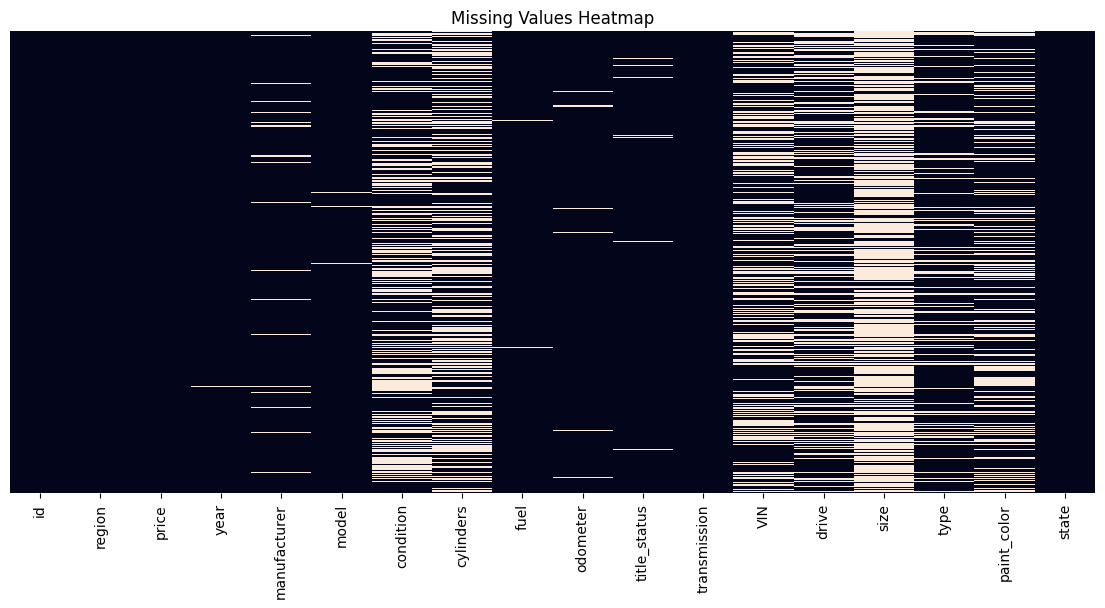

In [20]:
plt.figure(figsize=(14, 6))

sns.heatmap(data.isnull(),
            cbar=False,
            yticklabels=False)

plt.title('Missing Values Heatmap')
plt.show()

### Modeling

With your (almost?) final dataset in hand, it is now time to build some models.  Here, you should build a number of different regression models with the price as the target.  In building your models, you should explore different parameters and be sure to cross-validate your findings.

In [21]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold, GridSearchCV

from sklearn.compose import ColumnTransformer
from sklearn.compose import TransformedTargetRegressor

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Load dataset
data = pd.read_csv('/content/sample_data/vehicles.csv')


In [22]:
# Remove records without a valid target price
data = data.dropna(subset=['price'])
data = data[data['price'] > 0].copy()

print("Dataset shape:", data.shape)
print(data.head())


Dataset shape: (393985, 18)
           id                  region  price  year manufacturer model  \
0  7222695916                prescott   6000   NaN          NaN   NaN   
1  7218891961            fayetteville  11900   NaN          NaN   NaN   
2  7221797935            florida keys  21000   NaN          NaN   NaN   
3  7222270760  worcester / central MA   1500   NaN          NaN   NaN   
4  7210384030              greensboro   4900   NaN          NaN   NaN   

  condition cylinders fuel  odometer title_status transmission  VIN drive  \
0       NaN       NaN  NaN       NaN          NaN          NaN  NaN   NaN   
1       NaN       NaN  NaN       NaN          NaN          NaN  NaN   NaN   
2       NaN       NaN  NaN       NaN          NaN          NaN  NaN   NaN   
3       NaN       NaN  NaN       NaN          NaN          NaN  NaN   NaN   
4       NaN       NaN  NaN       NaN          NaN          NaN  NaN   NaN   

  size type paint_color state  
0  NaN  NaN         NaN    az  
1  NaN

In [23]:
# Define target variable
y = data['price']

# Remove target and identifier columns
X = data.drop(
    columns=['price', 'id', 'VIN'],
    errors='ignore'
)

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['year', 'odometer']
Categorical features: ['region', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'title_status', 'transmission', 'drive', 'size', 'type', 'paint_color', 'state']


### Evaluation

With some modeling accomplished, we aim to reflect on what we identify as a high-quality model and what we are able to learn from this.  We should review our business objective and explore how well we can provide meaningful insight into drivers of used car prices.  Your goal now is to distill your findings and determine whether the earlier phases need revisitation and adjustment or if you have information of value to bring back to your client.

In [26]:
#Split the dataset.We will use an 80/20 split.
#- 80% for model training and cross-validation.
#- 20% for final testing
# Sample dataset for initial model development
if len(X) > 50000:
    sample_data = data.sample(
        n=50000,  random_state=42)
else:
    sample_data = data.copy()

X = sample_data.drop(
    columns=['price', 'id', 'VIN'],
    errors='ignore'
)

y = sample_data['price']

# Training and testing split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20, random_state=42
)

In [27]:
#Handle missing values and encode categorical variables
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        min_frequency=50
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)


In [28]:
#Build multiple regression models
models = {
    'Linear Regression': LinearRegression(),

    'Ridge Regression': Ridge(),

    'Random Forest': RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),

    'Extra Trees': ExtraTreesRegressor(
        random_state=42,
        n_jobs=-1
    )
}

In [29]:
#Hyperparameter tuning and cross-validation
# Hyperparameter grids
param_grids = {
    'Linear Regression': {},

    'Ridge Regression': {
        'regressor__model__alpha': [0.1, 1, 10, 100]
    },

    'Random Forest': {
        'regressor__model__max_depth': [20, None],
        'regressor__model__min_samples_leaf': [2, 5]
    },

    'Extra Trees': {
        'regressor__model__max_depth': [20, None],
        'regressor__model__min_samples_leaf': [2, 5]
    }
}

# Cross-validation strategy
cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

results = []
best_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    # Create preprocessing and regression pipeline
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    # Apply log transformation to target
    reg_model = TransformedTargetRegressor(
        regressor=pipeline,
        func=np.log1p,
        inverse_func=np.expm1
    )

    # Grid search with cross-validation
    grid_search = GridSearchCV(
        estimator=reg_model,
        param_grid=param_grids[name],
        cv=cv,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    best_models[name] = grid_search.best_estimator_

    results.append({
        'Model': name,
        'Best CV RMSE': -grid_search.best_score_,
        'Best Parameters': grid_search.best_params_
    })

    print("Best Parameters:", grid_search.best_params_)
    print("Best CV RMSE:", -grid_search.best_score_)


Training Linear Regression...
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Best Parameters: {}
Best CV RMSE: 114137.40253324904

Training Ridge Regression...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Parameters: {'regressor__model__alpha': 10}
Best CV RMSE: 114130.3881711326

Training Random Forest...
Fitting 3 folds for each of 4 candidates, totalling 12 fits


KeyboardInterrupt: 

In [30]:
#Compare model performance
# Display cross-validation results
cv_results = pd.DataFrame(results)

cv_results = cv_results.sort_values(
    by='Best CV RMSE'
)

print(cv_results.to_string(index=False))

            Model  Best CV RMSE                 Best Parameters
 Ridge Regression 114130.388171 {'regressor__model__alpha': 10}
Linear Regression 114137.402533                              {}


In [31]:
#Next, evaluate each best model against the independent test dataset.
test_results = []

for name, model in best_models.items():

    # Predict used car prices
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(y_test, y_pred)

    test_results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

# Display results
test_results_df = pd.DataFrame(test_results)

test_results_df = test_results_df.sort_values(
    by='RMSE'
)

print(test_results_df)

               Model          MAE          RMSE  R2 Score
0  Linear Regression  7930.952172  12195.125293  0.331866
1   Ridge Regression  7900.010919  12197.215372  0.331637


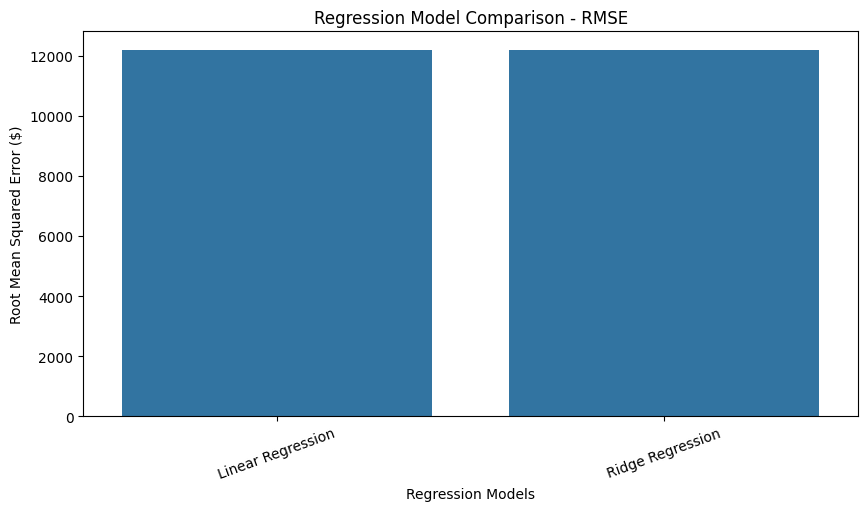

In [32]:
# Step H: Visualize model comparison

plt.figure(figsize=(10, 5))

sns.barplot(
    data=test_results_df,
    x='Model',
    y='RMSE'
)

plt.title('Regression Model Comparison - RMSE')
plt.xlabel('Regression Models')
plt.ylabel('Root Mean Squared Error ($)')
plt.xticks(rotation=20)

plt.show()


In [33]:
#Identify important price drivers
from sklearn.inspection import permutation_importance

# Identify the best-performing model
best_model_name = test_results_df.iloc[0]['Model']

best_model = best_models[best_model_name]

# Use a smaller test sample for efficiency
X_imp = X_test.sample(
    n=min(3000, len(X_test)),
    random_state=42
)

y_imp = y_test.loc[X_imp.index]

# Calculate permutation importance
importance = permutation_importance(
    best_model,
    X_imp,
    y_imp,
    n_repeats=3,
    random_state=42,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

# Create importance dataframe
feature_importance = pd.DataFrame({
    'Feature': X_imp.columns,
    'Importance': importance.importances_mean
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

         Feature   Importance
1           year  1356.163858
0         region  1150.754277
6           fuel  1073.831669
14         state  1007.382013
12          type   766.238945
2   manufacturer   509.287090
3          model   385.168261
9   transmission   262.135608
4      condition   232.604623
7       odometer   221.623757
5      cylinders   182.789980
11          size    82.273881
10         drive    73.856532
8   title_status    59.844287
13   paint_color    28.792491


In [ ]:
#Visualize the results:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Drivers of Used Car Prices')
plt.xlabel('Permutation Importance')
plt.ylabel('Vehicle Features')

plt.show()


### Deployment

Now that we've settled on our models and findings, it is time to deliver the information to the client.  You should organize your work as a basic report that details your primary findings.  Keep in mind that your audience is a group of used car dealers interested in fine-tuning their inventory.

 Expected business interpretation
After executing the models, we can investigate whether the following factors have significant predictive influence:
- Year: Newer vehicles generally command higher resale prices.
- Odometer: Higher mileage may reduce resale value.
- Manufacturer: Brand reputation and market demand may influence pricing.
- Condition: Better vehicle condition may increase resale value.
- Model: Certain vehicle models may command higher prices.
- Fuel type: Electric, hybrid, diesel, and gasoline vehicles may have different pricing patterns.
- Vehicle type: SUVs, trucks, sedans, and pickups may exhibit different price distributions.
- Geography: Regional supply and demand may influence used-car prices.
These are hypotheses to investigate, not conclusions until we examine the actual model results.

 Final deliverables for the Modeling phase
results are in the following format:
Model	Cross-validation RMSE	Test MAE	Test RMSE	Test R²
Linear Regression	To calculate	To calculate	To calculate	To calculate
Ridge Regression	To calculate	To calculate	To calculate	To calculate
Random Forest	To calculate	To calculate	To calculate	To calculate
Extra Trees	To calculate	To calculate	To calculate	To calculate

Important: The best model should not be selected solely based on the lowest training error. We should prioritize cross-validation consistency and independent test performance.

Also, because our dataset contains extreme vehicle prices, we should investigate whether the model's performance changes when unusual prices are handled differently. This is an important model robustness check.

CRISP-DM outcome: We will have multiple trained regression models, optimized hyperparameters, cross-validation results, independent test metrics, and an analysis of the most influential features affecting used-car prices.